In [618]:
import os
from PIL import Image
import pandas as pd
import seaborn as seaborn
from PIL import Image, ImageChops
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np

## Vérification nombre d'images de chaque tumeur Training

Ce code permet d'afficher les types de tumeur différentes et le nombre d'images associés à chacune des tumeurs.

In [619]:
liste_tumeur = {}                                                   # On initialise un dictionnaire vide pour stocker chaque tumeurs et le nombre d'images associées

dossier = os.listdir("Dataset/Training")                            # C'est le dossier que l'on va parcourir pour trouver les différentes tumeurs

for k in dossier:                                                   # La boucle qui permet de parcours le dossier pour trouver les différents dossiers relatifs à chaque tumeur
    if k not in liste_tumeur:
        liste_tumeur[k] = 0                                         # On ajoute à la boucle que si elle n'est pas déjà présente dans le dictionnaire

print (f"Liste des différentes tumeurs : {liste_tumeur}") 

for j in liste_tumeur:                                              # On parcourt tout le dictionnaire qui vient d'être rempli 
    dossier_actuel = os.path.join("Dataset/Training", j)            # Les dossiers à parcourir sont donc les différents dossier de tumeurs
    for l in os.listdir(dossier_actuel):
        liste_tumeur[j] += 1                                        # On ajoute 1 à chaque image de chaque tumeurs

print (f"Nombre d'images de chaque tumeur : {liste_tumeur}") 

Liste des différentes tumeurs : {'notumor': 0, 'meningioma': 0, 'pituitary': 0, 'glioma': 0}
Nombre d'images de chaque tumeur : {'notumor': 1400, 'meningioma': 1400, 'pituitary': 1400, 'glioma': 1400}


## Graphique nombre d'image de chaque tumeur Training

<Axes: xlabel='Type_Tumeur', ylabel='Count'>

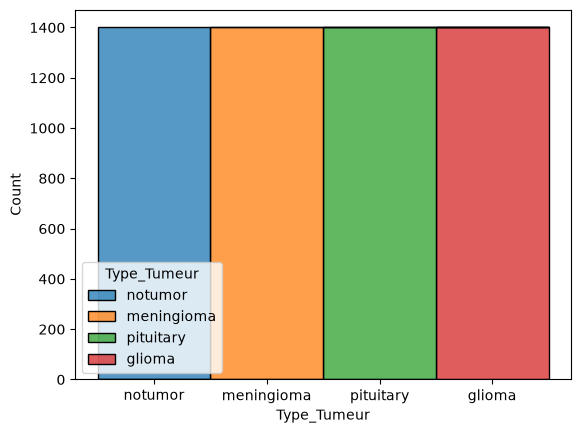

In [620]:
df = pd.DataFrame(list(liste_tumeur.items()), columns=['Type_Tumeur', 'Valeur'])                        # Pour faire un graphique, on transforme le dictionnaire en Dataframe
seaborn.histplot(data=df, x='Type_Tumeur', weights='Valeur', hue='Type_Tumeur', multiple='stack')       # Création du graphique

## Début préprocess (Récupération des infos des images)

In [621]:
df.head()                                                                   # class de df
df.info()                                                                   # infos du nombre d'entrée du df
df.describe()                                                               # Description df (nombre colonne / infos à l'interieur ...)

liste_taille = {}                                                           # On initialise 3 nouveeux dictionnaires pour les 3 vérifications
liste_format = {}
liste_couleur = {}

for j in liste_tumeur.keys():                                               # On va parcourir les différents dossier de tumeurs et regarder les images
    dossier_actuel = os.path.join("Dataset/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset/Training", j, l)
        img = Image.open(fichier_actuel)
        if img.size not in liste_taille.keys():                             # Ajout des différentes dimensions des images
            liste_taille[img.size] = 1
        else:
            liste_taille[img.size] += 1
        if img.format not in liste_format.keys():                           # Ajout de différent format de compression d'image (PNG, JPEG ...)
            liste_format[img.format] = 1
        else:
            liste_format[img.format] += 1 
        if img.mode not in liste_couleur:                                   # Ajout des différent mode de colorimétrie des images (J, RGB, RGBA ...)
            liste_couleur[img.mode] = 1
        else:
            liste_couleur[img.mode] += 1

taille_max = max(liste_taille, key=liste_taille.get)                        # Dimensions les plus présentes
format_max = max(liste_format, key=liste_format.get)                        # Format le plus présent
couleur_max = max(liste_couleur, key=liste_couleur.get)                     # Couleur la plus présente
print ("Type de dimensions : ", liste_taille)
print ("Type de formats : ", liste_format)
print ("Type de couleurs : ", liste_couleur)
print("Dimensions les plus présentes :", str(taille_max) + ". Nombre d'images avec ces dimensions :", liste_taille[taille_max])
print("Format le plus présent :", format_max + ". Nombre d'images avec ce format :", liste_format[format_max])
print("Couleur la plus présente :", couleur_max + ". Nombre d'images avec ce mode de colorimétrie :", liste_couleur[couleur_max])

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Type_Tumeur  4 non-null      str  
 1   Valeur       4 non-null      int64
dtypes: int64(1), str(1)
memory usage: 196.0 bytes
Type de dimensions :  {(235, 215): 1, (680, 680): 12, (225, 225): 253, (236, 300): 2, (228, 221): 32, (1024, 1024): 5, (194, 259): 8, (550, 664): 15, (350, 393): 6, (215, 234): 19, (150, 198): 33, (630, 630): 69, (236, 213): 17, (214, 236): 19, (512, 512): 4012, (206, 244): 26, (235, 214): 10, (350, 350): 11, (173, 201): 26, (177, 197): 6, (236, 240): 1, (207, 243): 11, (926, 649): 2, (359, 449): 16, (218, 231): 22, (442, 454): 13, (212, 238): 8, (236, 262): 2, (236, 236): 39, (204, 247): 1, (236, 357): 5, (201, 251): 40, (232, 217): 32, (300, 168): 8, (605, 613): 2, (196, 257): 11, (339, 340): 12, (205, 249): 2, (441, 442): 13, (230, 282): 15, (208, 248): 4, (442, 442): 38, (450, 504): 1, (

## Première conclusion

Tout d'abord, à la base, on à bien vérifier qu'il y a bien le <b>même nombre d'images</b> pour CHAQUE tumeur, et pour les images SANS tumeurs.

On peut le remarquer via les <b>première vérification</b> ainsi que le <u>graphique</u>. Nous avons en tout, <u>5600 images</u>, réparties en <b>4 catégories</b>, ce qui fait 1400 images par catégorie.

Ensuite, nous avons vérifier les <u>différents éléments</u> de chaques images. Comme leurs <b>dimensions</b>, leurs <b>formats</b> et leurs <b>colorimétries.</b>

On a pu voir que sur les <u>5600 images</u>, 4012 était en (512, 512) ce qui va très certainement devenir nos dimensions par défaut. <b>Cependant</b> il faudra faire attention, car certaines images ne sont pas des carrés. Signifiant qu'une conversion sans vérification pourrait applatir ou couper l'image. 

Ensuite, il y en a 5596 en <b>JPEG</b> et 4 en format <b>PNG</b>, bien que noté comme JPEG. Malgré que ces deux formats de compressions soient différents, nous ne trouvons pas cela dérangeant et <u>décidons de ne pas toucher à ces quatres images</u>. Les enlever serai complément contre-productif étant donné qu'elles reste exploitables comme les autres, et peuvent être comparées entre-elles sans difficultés.

Et enfin, leurs colorimétrie. Le plus courant est le <b>RGB</b> avec 3238 images, cependant, malgré qu'elle soit noté comme en <b>RGB</b>, un IRM n'utilise que des nuances de gris, signifiant que la transformation de toutes les images en mode <b>L (Lab / ou CIELLaB)</b> c'est à dire avec des nuances de gris sur une échelle de 0 à 100. 

Pour notre première étape de normalisation, nous décidons donc : 

- <u>De passer toutes les images en noir et blanc.
- De passer toutes les images en dimensions (512, 512)
- De laisser les images avec leurs modes car 99.9% sont en JPEG</u>

## Premier Preprocess

In [622]:
for j in liste_tumeur.keys():                                                               # On va reparcourir toutes les images
    dossier_actuel = os.path.join("Dataset/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset/Training", j, l)
        Dossier_cible = os.path.join("Dataset_clean/Training", j)
        img = Image.open(fichier_actuel)
        if img.mode not in ("L", "l"):                                                      # Si l'image n'est pas en noir et blanc, alors on la convertit
            img = img.convert('L')

        if img.size != (512, 512):                                                          # Si l'image n'est pas en dimensions (512, 512), on la resize
            img = Image.open(fichier_actuel)
            ratio = 512 / max(img.size)

            nouvelle_taille = (int(img.size[0] * ratio), int(img.size[1] * ratio))
            img = img.resize(nouvelle_taille)
            nouvelle_img = Image.new("L", (512, 512))

            x = (512 - img.size[0]) // 2
            y = (512 - img.size[1]) // 2

            nouvelle_img.paste(img, (x, y))
        
            os.makedirs(Dossier_cible, exist_ok=True)
            nouvelle_img.save(os.path.join(Dossier_cible, l))                               # On sauvegarde les images dans un nouvea dossier Dataset_clean
        else:
            os.makedirs(Dossier_cible, exist_ok=True)
            img.save(os.path.join(Dossier_cible, l))

In [623]:
for j in liste_tumeur.keys():                                               # Vérification que toutes les images sont dans les mêmes formats (dimensions, colorimétrie)
    dossier_actuel = os.path.join("Dataset_clean/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset_clean/Training", j, l)
        img = Image.open(fichier_actuel)
        print 
        if img.size != (512, 512):
            print("MAUVAISES DIMENSIONS DETECTEES")

## Vérification des doublons.

In [624]:
i = 0

for j in liste_tumeur.keys():
    dossier_actuel = os.path.join("Dataset_clean/Training", j)
    for l in os.listdir(dossier_actuel):
        if i > 0:
            image_actuel = os.path.join("Dataset_clean/Training", j, l)
            img1 = Image.open(image_actuel)
            img2 = Image.open(image_precedente)
            print ("image 1 =", img1, "image 2 =", img2)
            print (ImageChops.difference(img1, img2))
        image_precedente = os.path.join("Dataset_clean/Training", j, l)
        i +=1

image 1 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EEFF57080> image 2 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EF401BA10>
<PIL.Image.Image image mode=L size=512x512 at 0x770EF4015C10>
image 1 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EF401BC80> image 2 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EF4019430>
<PIL.Image.Image image mode=L size=512x512 at 0x770EF4015C10>
image 1 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EF401B200> image 2 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EF4018110>
<PIL.Image.Image image mode=L size=512x512 at 0x770EF4015C10>
image 1 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EF4019430> image 2 = <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512 at 0x770EF401B200>
<PIL.Image.Image image mode=L size=512x512 at 0x770EF4015C10>
image 1 = <PIL.JpegImagePlugin.J

In [625]:
# knn = KNeighborsClassifier(n_neighbors=9)

# knn.fit(X_train_plat, y_train)

# y_pred = knn.predict(X_test_plat)


# accuracy = accuracy_score(y_test, y_pred)

# print("Accuracy :", accuracy)

# def load_one_image(file, img_size=imgs_size):
#     images = []

#     img = Image.open(file)
#     img = img.convert("L") # Convertion en Noir et blanc grayscale True
#     img = img.resize(img_size) # Resize les images pour les avoir toutes dans le même format
#     images.append(np.asarray(img, dtype=np.float32) / 255.0)    # Ajout de la nouvelle image dans images

#     return np.stack(images)

# nouvelle_image = load_one_image("Testing/glioma/Te-gl_18.jpg")

# nouvelle_image_plat = nouvelle_image.reshape(nouvelle_image.shape[0], -1)

# prediction = knn.predict(nouvelle_image_plat)

# print(X[prediction[0]])

# # X = CSVIris[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
# # y = CSVIris["Species"]

# # X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# # neigh = KNeighborsClassifier(n_neighbors=16)
# # neigh.fit(X_train, y_train)
# # y_pred = neigh.predict(X_test)

# # print("Score train:", neigh.score(X_train, y_train))
# # print("Score test:", neigh.score(X_test, y_test))

# # nouvelles_fleurs = pd.DataFrame({
# #     "SepalLengthCm": [5.2, 6.78, 6.65],
# #     "SepalWidthCm":  [3.9, 4.96, 4.3],
# #     "PetalLengthCm": [2.35, 6.0, 3.0],
# #     "PetalWidthCm":  [1.17, 4.485, 2.21]
# # })

# # predictions = neigh.predict(nouvelles_fleurs)
# # print(predictions)
# # probas = neigh.predict_proba(nouvelles_fleurs)
# # print(probas)

In [626]:
# # Création des variables label et idx (id au pluriel)
# X = ["glioma", "meningioma", "notumor", "pituitary"]
# y = {name: id for id, name in enumerate(X)}

# # Dimension des images 256 par 256
# imgs_size = (256, 256)

# # Fonction permettant de donner un id de classe à chaques photos
# def listlabels(root_dir):
#     filepaths = []
#     labels = []

#     for k in X:
#         class_dossier = os.path.join(root_dir, k)
#         if not os.path.isdir(class_dossier):
#             raise FileNotFoundError(f"Dossier attendu introuvable : {class_dossier}")

#         for l in os.listdir(class_dossier):
#             if l.lower().endswith((".jpg", ".jpeg", ".png")):
#                 filepaths.append(os.path.join(class_dossier, l))    # 
#                 labels.append(y[k])  # Ajout de l'id de la classe de chaques photo dans labels

#     return filepaths, np.array(labels)

# # Fonction qui permet de récuper toutes les images et de les normaliser
# def load_images(filepaths, img_size=imgs_size):
#     images = []

#     for k in filepaths:
#         img = Image.open(k)
#         img = img.convert("L") # Convertion en Noir et blanc grayscale True
#         img = img.resize(img_size) # Resize les images pour les avoir toutes dans le même format
#         images.append(np.asarray(img, dtype=np.float32) / 255.0)    # Ajout de la nouvelle image dans images

#     return np.stack(images)



# train_paths, y_train = listlabels("Training")
# test_paths, y_test = listlabels("Testing")

# print(f"Train : {len(train_paths)} images")
# print(f"Test  : {len(test_paths)} images")

# for name, id in y.items():
#     print(f"{name} -> train: {np.sum(y_train == id)} | test: {np.sum(y_test == id)}")

# X_train = load_images(train_paths)
# X_test = load_images(test_paths)

# X_train_plat = X_train.reshape(X_train.shape[0], -1)
# X_test_plat = X_test.reshape(X_test.shape[0], -1)

# print(f"X_train : {X_train.shape}")
# print(f"X_test : {X_test.shape}")   

# print(X_train_plat.shape)
# print(X_test_plat.shape)

 # Modèle KNN


In [627]:
# knn = KNeighborsClassifier(n_neighbors=9)

# knn.fit(X_train_plat, y_train)

# y_pred = knn.predict(X_test_plat)


# accuracy = accuracy_score(y_test, y_pred)

# print("Accuracy :", accuracy)

# def load_one_image(file, img_size=imgs_size):
#     images = []

#     img = Image.open(file)
#     img = img.convert("L") # Convertion en Noir et blanc grayscale True
#     img = img.resize(img_size) # Resize les images pour les avoir toutes dans le même format
#     images.append(np.asarray(img, dtype=np.float32) / 255.0)    # Ajout de la nouvelle image dans images

#     return np.stack(images)

# nouvelle_image = load_one_image("Testing/glioma/Te-gl_18.jpg")

# nouvelle_image_plat = nouvelle_image.reshape(nouvelle_image.shape[0], -1)

# prediction = knn.predict(nouvelle_image_plat)

# print(X[prediction[0]])

# # X = CSVIris[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
# # y = CSVIris["Species"]

# # X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# # neigh = KNeighborsClassifier(n_neighbors=16)
# # neigh.fit(X_train, y_train)
# # y_pred = neigh.predict(X_test)

# # print("Score train:", neigh.score(X_train, y_train))
# # print("Score test:", neigh.score(X_test, y_test))

# # nouvelles_fleurs = pd.DataFrame({
# #     "SepalLengthCm": [5.2, 6.78, 6.65],
# #     "SepalWidthCm":  [3.9, 4.96, 4.3],
# #     "PetalLengthCm": [2.35, 6.0, 3.0],
# #     "PetalWidthCm":  [1.17, 4.485, 2.21]
# # })

# # predictions = neigh.predict(nouvelles_fleurs)
# # print(predictions)
# # probas = neigh.predict_proba(nouvelles_fleurs)
# # print(probas)